Loading 20 newsgroups dataset...
Training set size: 2338
Test set size: 1556
Categories: ['comp.graphics', 'rec.sport.baseball', 'sci.space', 'talk.politics.mideast']

Sample documents from each category:

--- comp.graphics ---
Apparently, my editor didn't do what I wanted it to do, so I'll try again.

i'm looking for any programs or code to do simple animation and/or
drawing using fractals in TurboPascal for an IBM
        ...

--- rec.sport.baseball ---
[about the infield fly rule]
	Unless he's Deion Sanders, in which case he just heads back to the
dugout and waits for his next base-running-blunder opportunity.

--- sci.space ---


Well, there already is a sulfate process for TiO2 purification.  The
chlorine process is cleaner, however, and for that reason is achieving
dominance in the marketplace.

Most Ti is used in pigment,...

--- talk.politics.mideast ---

Proven?  Maybe not.  But it can certainly be verified beyond a reasonable doubt.  This
statement and statements like it are 

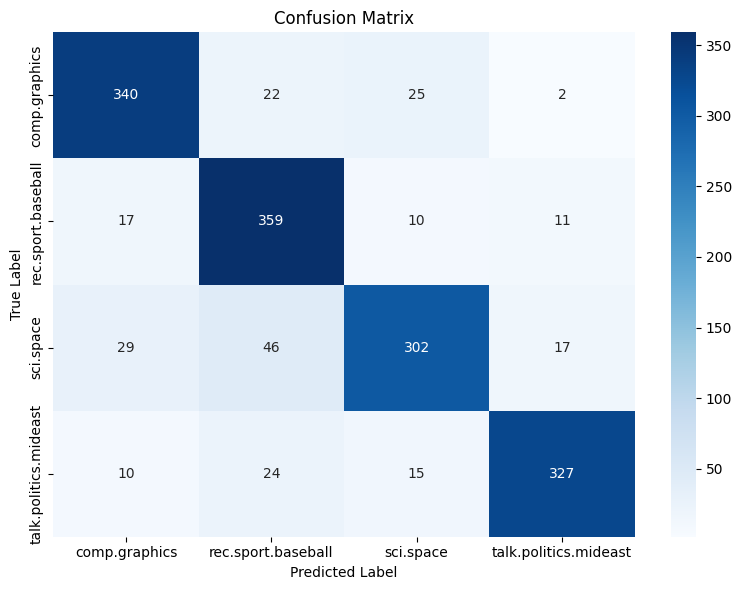


Testing with new documents...

Predictions for test documents:

Document: The astronauts conducted experiments on the International Sp...
Predicted category: sci.space
Probability distribution:
  comp.graphics: 0.0596
  rec.sport.baseball: 0.0310
  sci.space: 0.8475
  talk.politics.mideast: 0.0619

Document: The new graphics card delivers stunning performance for gami...
Predicted category: comp.graphics
Probability distribution:
  comp.graphics: 0.8550
  rec.sport.baseball: 0.0736
  sci.space: 0.0475
  talk.politics.mideast: 0.0238

Document: The baseball pitcher threw a perfect game last night...
Predicted category: rec.sport.baseball
Probability distribution:
  comp.graphics: 0.0088
  rec.sport.baseball: 0.9678
  sci.space: 0.0147
  talk.politics.mideast: 0.0088

Document: The peace talks in the Middle East continue next week...
Predicted category: talk.politics.mideast
Probability distribution:
  comp.graphics: 0.0477
  rec.sport.baseball: 0.3336
  sci.space: 0.0606
  talk.politic

AttributeError: 'MultinomialNB' object has no attribute 'coef_'

In [1]:
import pandas as pd
import numpy as np
from sklearn.datasets import fetch_20newsgroups
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import make_pipeline
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

# 1. Data ရယူခြင်း
categories = ['sci.space', 'comp.graphics', 'rec.sport.baseball', 'talk.politics.mideast']

print("Loading 20 newsgroups dataset...")
newsgroups_train = fetch_20newsgroups(subset='train', categories=categories, 
                                      remove=('headers', 'footers', 'quotes'), 
                                      shuffle=True, random_state=42)
newsgroups_test = fetch_20newsgroups(subset='test', categories=categories, 
                                     remove=('headers', 'footers', 'quotes'), 
                                     shuffle=True, random_state=42)

print(f"Training set size: {len(newsgroups_train.data)}")
print(f"Test set size: {len(newsgroups_test.data)}")
print(f"Categories: {newsgroups_train.target_names}")

# 2. Data ကို ကြည့်ရှုခြင်း
print("\nSample documents from each category:")
for i, category in enumerate(newsgroups_train.target_names):
    print(f"\n--- {category} ---")
    # ပထမဆုံး document ကို ရှာဖွေခြင်း
    first_doc_idx = np.where(newsgroups_train.target == i)[0][0]
    preview = newsgroups_train.data[first_doc_idx][:200] + "..." if len(newsgroups_train.data[first_doc_idx]) > 200 else newsgroups_train.data[first_doc_idx]
    print(preview)

# 3. Model တည်ဆောက်ခြင်း
print("\nBuilding the model...")
model = make_pipeline(
    TfidfVectorizer(stop_words='english', max_features=1000),
    MultinomialNB()
)

# 4. Model ကို training လုပ်ခြင်း
print("Training the model...")
model.fit(newsgroups_train.data, newsgroups_train.target)

# 5. Model ကို evaluation လုပ်ခြင်း
print("Evaluating the model...")
y_pred = model.predict(newsgroups_test.data)
accuracy = np.mean(y_pred == newsgroups_test.target)

print(f"\nTest Accuracy: {accuracy:.2%}")

# 6. Classification report
print("\nClassification Report:")
print(classification_report(newsgroups_test.target, y_pred, 
                           target_names=newsgroups_test.target_names))

# 7. Confusion matrix
cm = confusion_matrix(newsgroups_test.target, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=newsgroups_test.target_names,
            yticklabels=newsgroups_test.target_names)
plt.title('Confusion Matrix')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.tight_layout()
plt.show()

# 8. စမ်းသပ်မှုများ
print("\nTesting with new documents...")
test_documents = [
    "The astronauts conducted experiments on the International Space Station",
    "The new graphics card delivers stunning performance for gaming",
    "The baseball pitcher threw a perfect game last night",
    "The peace talks in the Middle East continue next week"
]

predictions = model.predict(test_documents)
predicted_probs = model.predict_proba(test_documents)

print("\nPredictions for test documents:")
for doc, pred, probs in zip(test_documents, predictions, predicted_probs):
    category = newsgroups_train.target_names[pred]
    print(f"\nDocument: {doc[:60]}...")
    print(f"Predicted category: {category}")
    print("Probability distribution:")
    for i, cat in enumerate(newsgroups_train.target_names):
        print(f"  {cat}: {probs[i]:.4f}")

# 9. Feature importance (most indicative words)
print("\nMost important words for each category:")
feature_names = model.named_steps['tfidfvectorizer'].get_feature_names_out()
for i, category in enumerate(newsgroups_train.target_names):
    # Naive Bayes coefficients (log probabilities)
    coef = model.named_steps['multinomialnb'].coef_[i]
    # Top 10 words for this category
    top10 = np.argsort(coef)[-10:][::-1]
    top10_words = [feature_names[idx] for idx in top10]
    print(f"\n{category}: {', '.join(top10_words)}")